# Customer Segmentation using RFM Analysis
**Goal:** Group e-commerce customers by *how recently* (Recency), *how often* (Frequency) and *how much* (Monetary) they buy, so the business can treat each group differently.

> **How to use this notebook:** Run cell by cell (Shift+Enter). Read the *What / Why* before each code cell, try the **Practice** questions in a new cell below, then move on.
> *Telugu-English tip:* ప్రతి step లో first **ఏం చేస్తున్నాం (What)**, తర్వాత **ఎందుకు (Why)** అర్థం చేసుకోండి — code తర్వాత easy అవుతుంది.

## Step 1 – Import libraries and set up
**What:** Load the Python libraries we need.
**Why:** Python by itself cannot handle tables or charts. Pandas = tables, NumPy = maths, Matplotlib/Seaborn = charts.

| Line | Meaning |
|---|---|
| `import pandas as pd` | Pandas library, short name `pd` |
| `import numpy as np` | NumPy library, short name `np` |
| `Path` | Safe way to write file paths on Windows/Mac/Linux |
| `sns.set_theme(...)` | Gives all charts a clean professional look |
| `warnings.filterwarnings` | Hides non-important warnings so output is clean |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# reuse the colour palette from src/config.py
sys.path.append(str(Path("..") / "src"))
from config import SEGMENT_COLORS, SEGMENT_ORDER

print("Pandas version:", pd.__version__)
print("Libraries loaded successfully")

Pandas version: 3.0.6
Libraries loaded successfully


**Expected output:** Pandas version number and the success message.

**Practice 1:** (a) Print the NumPy version with `np.__version__`. (b) What is the difference between `import pandas` and `import pandas as pd`?

## Step 2 – Load and understand the dataset
**What:** Read the CSV (or the real UCI Excel file) into a DataFrame and look at it.
**Why:** Before analysing anything we must know the columns, data types, and size. *Data ni artham chesukokunda analysis cheyyakudadu.*

**Dataset columns (UCI Online Retail format):**
| Column | Meaning |
|---|---|
| InvoiceNo | Order number. Starts with **C** = cancelled order |
| StockCode | Product code |
| Description | Product name |
| Quantity | Units bought (negative = return) |
| InvoiceDate | Date & time of order |
| UnitPrice | Price of one unit |
| CustomerID | Customer identifier (can be missing) |
| Country | Customer country |

Code explanation: `dtype={...}` keeps InvoiceNo/StockCode as text (some contain letters). `parse_dates` converts text to real dates. If you downloaded the real UCI file `Online Retail.xlsx` into `/data`, the code loads it automatically.

In [2]:
DATA_DIR = Path("..") / "data"
real_file = DATA_DIR / "Online Retail.xlsx"
sample_file = DATA_DIR / "online_retail_sample.csv"

if real_file.exists():
    df = pd.read_excel(real_file, dtype={"InvoiceNo": str, "StockCode": str})
    print("Loaded REAL UCI dataset")
else:
    df = pd.read_csv(sample_file, dtype={"InvoiceNo": str, "StockCode": str},
                     parse_dates=["InvoiceDate"])
    print("Loaded SAMPLE dataset")

print("Shape (rows, columns):", df.shape)
df.head()

Loaded SAMPLE dataset
Shape (rows, columns): (138144, 8)


  InvoiceNo StockCode          Description  Quantity         InvoiceDate  \
0    550349     10056          RED LANTERN         3 2010-12-02 08:48:00   
1    550349     10007  HANGING STORAGE JAR         3 2010-12-02 08:48:00   
2   C550349     11498       SILVER DOORMAT        -2 2010-12-02 08:48:00   
3    550349     11484      WOODEN NOTEBOOK         2 2010-12-02 08:48:00   
4    550349     11127          RED DOORMAT         6 2010-12-02 08:48:00   

   UnitPrice  CustomerID         Country  
0       2.10   14,441.00  United Kingdom  
1      12.75   14,441.00  United Kingdom  
2       9.95   14,441.00  United Kingdom  
3       9.95   14,441.00  United Kingdom  
4       1.25   14,441.00  United Kingdom  

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138144 entries, 0 to 138143
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    138144 non-null  str           
 1   StockCode    138144 non-null  str           
 2   Description  137458 non-null  str           
 3   Quantity     138144 non-null  int64         
 4   InvoiceDate  138144 non-null  datetime64[us]
 5   UnitPrice    138144 non-null  float64       
 6   CustomerID   117409 non-null  float64       
 7   Country      138144 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 8.4 MB


In [4]:
df.describe()

        Quantity                 InvoiceDate  UnitPrice  CustomerID
count 138,144.00                      138144 138,144.00  117,409.00
mean        4.37  2011-06-05 17:01:20.919909       4.70   13,859.62
min       -46.00         2010-12-02 08:48:00       0.00   12,347.00
25%         2.00         2011-03-21 15:53:00       1.25   13,107.00
50%         3.00         2011-05-22 11:02:00       2.95   13,910.00
75%         6.00         2011-08-25 16:05:00       6.95   14,582.00
max        24.00         2011-12-09 17:39:00      16.95   15,346.00
std         4.72                         NaN       4.71      862.86

**What to notice:** `Quantity` has negative values (returns/cancellations), `CustomerID` has fewer non-null values than other columns (missing IDs), and `UnitPrice` has zeros. Those are the *dirty* parts we clean next.

**Practice 2:** (a) How many unique countries are there? (`df["Country"].nunique()`) (b) What is the date range of the data? (`df["InvoiceDate"].min()`, `.max()`) (c) How many unique products?

## Step 3 – Check data quality
**What:** Count missing values, duplicates, cancelled orders and invalid numbers.
**Why:** Wrong data → wrong customers → wrong business decisions. *Garbage in, garbage out.*

In [5]:
print("MISSING VALUES")
print(df.isnull().sum())
print("\nMissing % in CustomerID:", round(df["CustomerID"].isnull().mean() * 100, 1), "%")

print("\nDuplicate rows:", df.duplicated().sum())
print("Cancelled invoices (start with C):", df["InvoiceNo"].str.startswith("C").sum())
print("Rows with Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

MISSING VALUES
InvoiceNo          0
StockCode          0
Description      686
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID     20735
Country            0
dtype: int64

Missing % in CustomerID: 15.0 %

Duplicate rows: 1367
Cancelled invoices (start with C): 2763
Rows with Quantity <= 0: 2802
Rows with UnitPrice <= 0: 25


**Line by line:** `isnull().sum()` counts blanks per column. `.mean()` of True/False gives the fraction of True. `duplicated()` marks repeated identical rows. `str.startswith("C")` finds cancellations.

**Why can't we keep rows without CustomerID?** RFM is *per customer*. If we do not know who bought, we cannot calculate their R, F or M.

**Practice 3:** How much revenue (Quantity × UnitPrice) is in rows with missing CustomerID? Is it a big share?

## Step 4 – Clean the data
**What:** Remove duplicates, missing CustomerIDs, cancelled orders, invalid quantity/price and non-product codes (POST, M, D…).
**Why:** Only real completed purchases should count as customer behaviour.

We keep a *cleaning log* so we can explain in interviews exactly how many rows each step removed.

In [6]:
log = [("Raw rows", len(df))]
clean = df.copy()

clean = clean.drop_duplicates()
log.append(("Remove duplicates", len(clean)))

clean = clean.dropna(subset=["CustomerID"])
log.append(("Drop missing CustomerID", len(clean)))

clean = clean[~clean["InvoiceNo"].str.upper().str.startswith("C")]
log.append(("Remove cancelled invoices", len(clean)))

clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]
log.append(("Remove Quantity<=0 or Price<=0", len(clean)))

non_product = r"^(POST|D|M|DOT|BANK CHARGES|C2|CRUK|S|AMAZONFEE)$"
clean = clean[~clean["StockCode"].str.upper().str.match(non_product)]
log.append(("Remove non-product codes", len(clean)))

# tidy types
clean["CustomerID"] = clean["CustomerID"].astype(int)
clean["Description"] = clean["Description"].fillna("UNKNOWN").str.strip().str.upper()
clean = clean.reset_index(drop=True)

log_df = pd.DataFrame(log, columns=["Step", "Rows_remaining"])
log_df["Rows_removed"] = -log_df["Rows_remaining"].diff().fillna(0).astype(int)
print(log_df.to_string(index=False))

                          Step  Rows_remaining  Rows_removed
                      Raw rows          138144             0
             Remove duplicates          136777          1367
       Drop missing CustomerID          116261         20516
     Remove cancelled invoices          113940          2321
Remove Quantity<=0 or Price<=0          113886            54
      Remove non-product codes          113840            46


**Line by line:**
- `~` means NOT. `~(...startswith("C"))` keeps rows that do **not** start with C.
- `&` means AND (use brackets around each condition).
- `astype(int)` converts 14441.0 → 14441.
- `diff()` = difference with the previous row, which shows how many rows each step removed.

**Practice 4:** What percentage of the raw rows did we keep? Write the formula using `len(clean)` and `len(df)`.

## Step 5 – Calculate Total Sales and headline KPIs
**What:** Create `TotalSales = Quantity × UnitPrice` and compute revenue, customers, orders, AOV.
**Why:** Revenue per line is the base of Monetary value. AOV (Average Order Value) = Revenue ÷ Orders.

In [7]:
clean["TotalSales"] = (clean["Quantity"] * clean["UnitPrice"]).round(2)
clean["InvoiceMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)

total_revenue = clean["TotalSales"].sum()
total_customers = clean["CustomerID"].nunique()
total_orders = clean["InvoiceNo"].nunique()
aov = total_revenue / total_orders

print(f"Total Revenue        : {total_revenue:,.2f}")
print(f"Total Customers      : {total_customers:,}")
print(f"Total Orders         : {total_orders:,}")
print(f"Average Order Value  : {aov:,.2f}")
print(f"Orders per customer  : {total_orders / total_customers:.2f}")

Total Revenue        : 2,438,541.66
Total Customers      : 2,996
Total Orders         : 20,094
Average Order Value  : 121.36
Orders per customer  : 6.71


**Note:** `nunique()` = number of *distinct* values. One order (invoice) has many lines, so we count distinct `InvoiceNo` for orders.

**Practice 5:** Calculate the average revenue per customer. Which is bigger: AOV or revenue per customer? Why?

## Step 6 – Exploratory Data Analysis (EDA)
**What:** Look for patterns – countries, products, months, hours.
**Why:** EDA gives context and business stories for interviews, and tells us whether the data looks reasonable.

In [8]:
print("TOP 5 COUNTRIES BY REVENUE")
print(clean.groupby("Country")["TotalSales"].sum().sort_values(ascending=False).head(5).round(0))

print("\nTOP 5 PRODUCTS BY QUANTITY SOLD")
print(clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(5))

print("\nMONTHLY REVENUE")
monthly = clean.groupby("InvoiceMonth").agg(Revenue=("TotalSales", "sum"),
                                            Orders=("InvoiceNo", "nunique"),
                                            Customers=("CustomerID", "nunique"))
print(monthly.round(0))

TOP 5 COUNTRIES BY REVENUE
Country
United Kingdom   2,085,896.00
Germany            103,741.00
France              59,058.00
Spain               41,027.00
EIRE                30,328.00
Name: TotalSales, dtype: float64

TOP 5 PRODUCTS BY QUANTITY SOLD
Description
RETRO TRAY             11557
CERAMIC CLOCK           8941
RETRO CUSHION COVER     7399
VINTAGE LUNCH BAG       7285
SILVER DOORMAT          7241
Name: Quantity, dtype: int64

MONTHLY REVENUE
                Revenue  Orders  Customers
InvoiceMonth                              
2010-12       44,020.00     392        222
2011-01      152,837.00    1305        553
2011-02      211,909.00    1708        733
2011-03      297,735.00    2409        998
2011-04      312,585.00    2577       1089
2011-05      266,056.00    2184       1032
2011-06      218,234.00    1782        908
2011-07      182,293.00    1520        804
2011-08      179,190.00    1476        754
2011-09      178,145.00    1493        805
2011-10      210,973.00    173

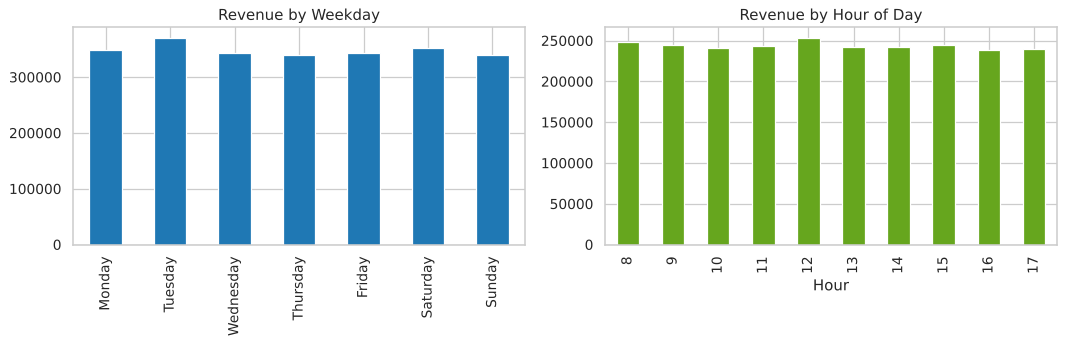

In [9]:
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()
clean["Hour"] = clean["InvoiceDate"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
clean.groupby("Weekday")["TotalSales"].sum().reindex(order).plot(kind="bar", ax=ax[0], color="#1f78b4")
ax[0].set_title("Revenue by Weekday"); ax[0].set_xlabel("")
clean.groupby("Hour")["TotalSales"].sum().plot(kind="bar", ax=ax[1], color="#66a61e")
ax[1].set_title("Revenue by Hour of Day")
plt.tight_layout(); plt.show()

**Practice 6:** (a) Which month has the highest revenue? (b) Which country apart from the United Kingdom brings the most revenue? (c) Create a chart of revenue by country (top 5).

## Step 7 – Customer purchasing behaviour
**What:** Summarise each customer: orders, spend, first/last purchase, average basket.
**Why:** This is the foundation of RFM. We also check the *80/20 (Pareto) rule*.

In [10]:
cust = clean.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "nunique"),
    Items=("Quantity", "sum"),
    Spend=("TotalSales", "sum"),
    First=("InvoiceDate", "min"),
    Last=("InvoiceDate", "max"),
)
cust["AvgOrderValue"] = cust["Spend"] / cust["Orders"]
print(cust.describe().round(1))

repeat_rate = (cust["Orders"] > 1).mean() * 100
print(f"\nRepeat customer rate: {repeat_rate:.1f}%")

# Pareto: share of revenue from the top 20% customers
cust_sorted = cust.sort_values("Spend", ascending=False)
top20 = cust_sorted.head(int(len(cust_sorted) * 0.2))["Spend"].sum()
print(f"Top 20% customers generate {top20 / cust['Spend'].sum() * 100:.1f}% of revenue")

        Orders    Items     Spend                       First  \
count 2,996.00 2,996.00  2,996.00                        2996   
mean      6.70   173.40    813.90  2011-05-16 21:36:04.866488   
min       1.00     1.00      0.40         2010-12-02 08:48:00   
25%       1.00    32.00    137.20         2011-02-11 12:44:30   
50%       3.00    79.00    384.70         2011-04-12 13:55:00   
75%      10.00   230.00  1,100.30         2011-08-31 13:35:00   
max      30.00 2,220.00 11,082.50         2011-12-08 09:32:00   
std       7.30   229.30  1,085.80                         NaN   

                             Last  AvgOrderValue  
count                        2996       2,996.00  
mean   2011-08-08 16:24:06.949265         120.90  
min           2010-12-02 08:48:00           0.40  
25%           2011-05-13 09:27:45          62.90  
50%           2011-09-19 14:54:00         103.70  
75%           2011-11-07 13:54:45         155.30  
max           2011-12-09 17:39:00         728.80  
std   

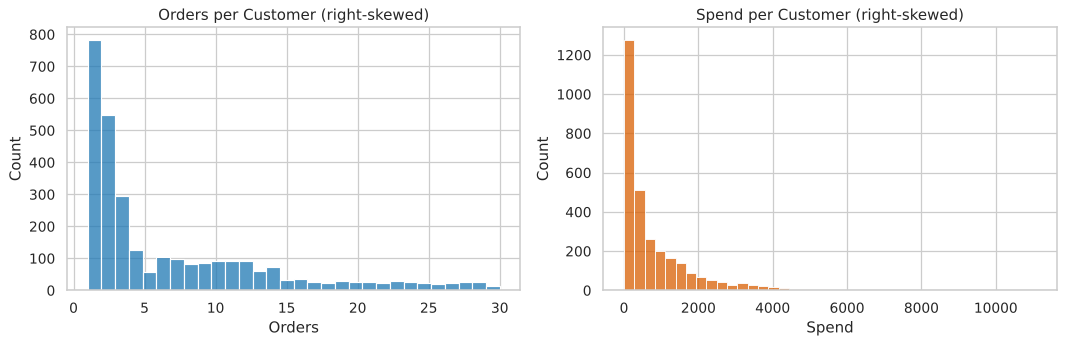

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(cust["Orders"], bins=30, ax=ax[0], color="#1f78b4")
ax[0].set_title("Orders per Customer (right-skewed)")
sns.histplot(cust["Spend"], bins=40, ax=ax[1], color="#d95f02")
ax[1].set_title("Spend per Customer (right-skewed)")
plt.tight_layout(); plt.show()

**Why skewed?** Few customers buy a lot; most buy a little. That is why we use **quintile scoring** (rank-based) instead of raw values.

**Practice 7:** How many customers placed only one order? How much revenue do they contribute?

## Step 8 – Calculate Recency, Frequency, Monetary
**What:** For every customer compute
- **Recency** = days since last purchase (small = good)
- **Frequency** = number of distinct orders (big = good)
- **Monetary** = total spend (big = good)

**Why:** These three numbers describe loyalty and value in a simple way.

**Snapshot date:** We pretend "today" is *one day after the last transaction* in the data. If we used the real today, every customer would look inactive because the data is old.

In [12]:
snapshot_date = clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date.date())

rfm = clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSales", "sum"),
).round(2).reset_index()

rfm.head(10)

Snapshot date: 2011-12-10


   CustomerID  Recency  Frequency  Monetary
0       12347      289          1    381.60
1       12348      273          1     33.48
2       12349      216          6    431.80
3       12350      248          3    810.32
4       12351       43          2    483.70
5       12352        8         26  3,871.48
6       12353      184          7  1,431.97
7       12354      308          1    125.25
8       12355      229          2     91.97
9       12356      131          1    226.57

In [13]:
rfm[["Recency", "Frequency", "Monetary"]].describe().round(1)

       Recency  Frequency  Monetary
count 2,996.00   2,996.00  2,996.00
mean    123.80       6.70    813.90
std     100.80       7.30  1,085.80
min       1.00       1.00      0.40
25%      33.00       1.00    137.20
50%      82.00       3.00    384.70
75%     211.00      10.00  1,100.30
max     373.00      30.00 11,082.50

**Practice 8:** (a) Find the customer with the lowest Recency. (b) Find the customer with the highest Monetary. (c) Why do we use `nunique()` for Frequency and not `count()`?

## Step 9 – RFM scoring (1 to 5)
**What:** Convert each metric into a 1–5 score using **quintiles** (`pd.qcut` splits customers into 5 equal groups).
**Why:** Scores make different units (days, orders, money) comparable.

| Metric | Direction | Labels |
|---|---|---|
| Recency | smaller = better | `[5,4,3,2,1]` (reversed!) |
| Frequency | bigger = better | `[1..5]` |
| Monetary | bigger = better | `[1..5]` |

**Important trick:** Frequency has many ties (lots of customers with 1 order) → `qcut` fails with duplicate edges. We use `rank(method="first")` first to break ties.

In [14]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm["RFM_Total"] = rfm[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

rfm.sort_values("RFM_Total", ascending=False).head(8)

      CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
759        13109       18         13  1,442.98        5        5        5   
5          12352        8         26  3,871.48        5        5        5   
2605       14956       19         22  4,482.21        5        5        5   
2587       14938       22         26  3,090.54        5        5        5   
1025       13375       14         30  2,924.04        5        5        5   
755        13105       24         24  2,190.61        5        5        5   
42         12389       25         15  2,232.09        5        5        5   
1748       14099       13         24  2,209.54        5        5        5   

     RFM_Score  RFM_Total  
759        555         15  
5          555         15  
2605       555         15  
2587       555         15  
1025       555         15  
755        555         15  
42         555         15  
1748       555         15  

In [15]:
# Validate: Recency should DEcrease as R_Score increases
print(rfm.groupby("R_Score")["Recency"].agg(["min", "max", "mean"]).round(1))
print()
print(rfm.groupby("F_Score")["Frequency"].agg(["min", "max", "mean"]).round(1))

         min  max   mean
R_Score                 
1        228  373 277.80
2        155  227 194.20
3         57  154  90.60
4         28   56  40.90
5          1   27  16.60

         min  max  mean
F_Score                
1          1    1  1.00
2          1    2  1.70
3          2    5  3.20
4          5   12  8.60
5         12   30 19.10


**Why validate?** A good analyst always checks that the scoring direction is right. R_Score 5 must have the *smallest* recency days.

**Practice 9:** (a) What does RFM_Score "555" mean? And "111"? (b) Why do we reverse the labels for Recency?

## Step 10 – Segment customers
**What:** Map (R, F) score combinations to 8 business segments.
**Why:** Marketing teams cannot act on 125 different RFM codes, but they can act on 8 named groups.

| Segment | Rule (R, F scores) | Business meaning | Action |
|---|---|---|---|
| **Champions** | R 4-5 and F 4-5 | Bought recently, buy often, spend most | Reward, early access, ask for reviews/referrals |
| **Loyal Customers** | R ≥ 3 and F ≥ 3 (not Champions, not 3-3) | Regular buyers with good spend | Upsell, loyalty programme |
| **Potential Loyalists** | R 4-5 and F = 2 | Recent customers with 2 orders | Membership offers, recommend products |
| **New Customers** | R 4-5 and F = 1 | Just made their first purchase | Welcome series, onboarding, second-purchase coupon |
| **Need Attention** | R = 3 and F ≤ 3 | Average recency/frequency; starting to cool | Limited-time offers, reactivation reminder |
| **At Risk** | R 1-2 and F 3-4 | Used to buy often, now silent | Personalised win-back, survey, discount |
| **Cannot Lose Them** | R 1-2 and F = 5 | Our best past buyers, now gone quiet | Call/email personally, special offer – highest priority |
| **Hibernating** | R 1-2 and F 1-2 | Low frequency and long inactive | Low-cost email, or stop spending marketing money |

Rules are checked **top to bottom; first match wins** (so every customer gets exactly one segment).

In [16]:
def assign_segment(r, f):
    if r >= 4 and f >= 4:
        return "Champions"
    if r >= 4 and f == 1:
        return "New Customers"
    if r >= 3 and f >= 3 and not (r == 3 and f == 3):
        return "Loyal Customers"
    if r == 3:
        return "Need Attention"
    if r >= 4:                      # r = 4 or 5, f = 2
        return "Potential Loyalists"
    if f == 5:                      # r = 1 or 2
        return "Cannot Lose Them"
    if f >= 3:
        return "At Risk"
    return "Hibernating"

rfm["Segment"] = [assign_segment(r, f) for r, f in zip(rfm["R_Score"], rfm["F_Score"])]

# Every customer must have exactly one segment
assert rfm["Segment"].notna().all()
print(rfm["Segment"].value_counts().reindex(SEGMENT_ORDER))

Segment
Champions              535
Loyal Customers        431
Potential Loyalists    277
New Customers          206
Need Attention         349
At Risk                482
Cannot Lose Them       175
Hibernating            541
Name: count, dtype: int64


**Practice 10:** A customer has R=5, F=1, M=4. Which segment? Another has R=2, F=5, M=5. Which segment? Which one should the business call personally?

## Step 11 – Segment profile and business insights
**What:** Calculate customers, share of revenue and average RFM per segment.
**Why:** This is the table you will show your manager/interviewer.

In [17]:
summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
).round(1)
summary["Customer_%"] = (summary["Customers"] / summary["Customers"].sum() * 100).round(1)
summary["Revenue_%"] = (summary["Total_Revenue"] / summary["Total_Revenue"].sum() * 100).round(1)
summary = summary.reindex(SEGMENT_ORDER)
summary

                     Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Segment                                                                    
Champions                  535        28.60          16.00      1,938.90   
Loyal Customers            431        67.50           6.80        852.80   
Potential Loyalists        277        25.70           1.70        228.60   
New Customers              206        28.30           1.00        120.10   
Need Attention             349        89.50           2.40        276.60   
At Risk                    482       219.50           5.80        696.60   
Cannot Lose Them           175       209.50          20.60      2,453.90   
Hibernating                541       258.70           1.30        155.00   

                     Total_Revenue  Customer_%  Revenue_%  
Segment                                                    
Champions             1,037,322.00       17.90      42.50  
Loyal Customers         367,570.60       14.40      15.10  

In [18]:
champ = summary.loc["Champions"]
risk = summary.loc[["At Risk", "Cannot Lose Them"]]
print(f"1) Champions are {champ['Customer_%']}% of customers but {champ['Revenue_%']}% of revenue.")
print(f"2) At Risk + Cannot Lose Them = {risk['Customers'].sum():.0f} customers holding "
      f"{risk['Revenue_%'].sum():.1f}% of revenue that is slipping away.")
print(f"3) Hibernating customers are {summary.loc['Hibernating','Customer_%']}% of the base but only "
      f"{summary.loc['Hibernating','Revenue_%']}% of revenue -> do not overspend on them.")

1) Champions are 17.9% of customers but 42.5% of revenue.
2) At Risk + Cannot Lose Them = 657 customers holding 31.4% of revenue that is slipping away.
3) Hibernating customers are 18.1% of the base but only 3.4% of revenue -> do not overspend on them.


**Practice 11:** Which segment has the highest average spend per customer? What marketing action would you suggest for the *Need Attention* segment?

## Step 12 – Visualisations
Six professional charts. Each one is also saved to `outputs/charts/` for the README and Power BI.

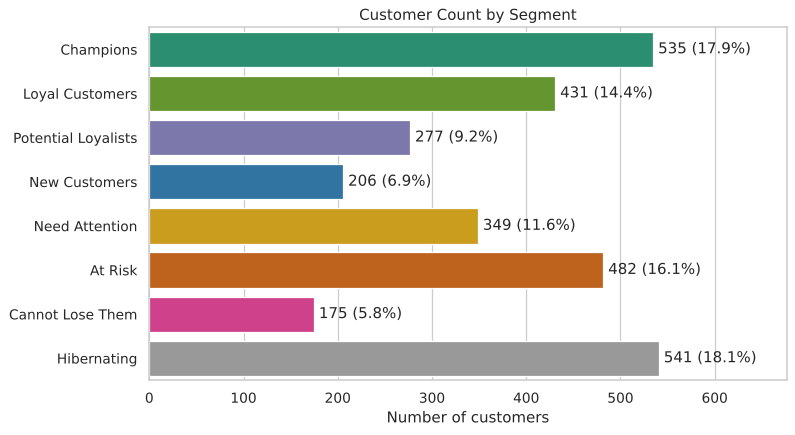

In [19]:
CHART_DIR = Path("..") / "outputs" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / name, dpi=150, bbox_inches="tight")

# ---- Chart 1: Customer count by segment ----
counts = rfm["Segment"].value_counts().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=counts.values, y=counts.index, hue=counts.index, palette=SEGMENT_COLORS, legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(v + 5, i, f"{v:,} ({v / counts.sum():.1%})", va="center")
ax.set(title="Customer Count by Segment", xlabel="Number of customers", ylabel="")
ax.set_xlim(0, counts.max() * 1.25)
save(fig, "01_customers_by_segment.png"); plt.show()

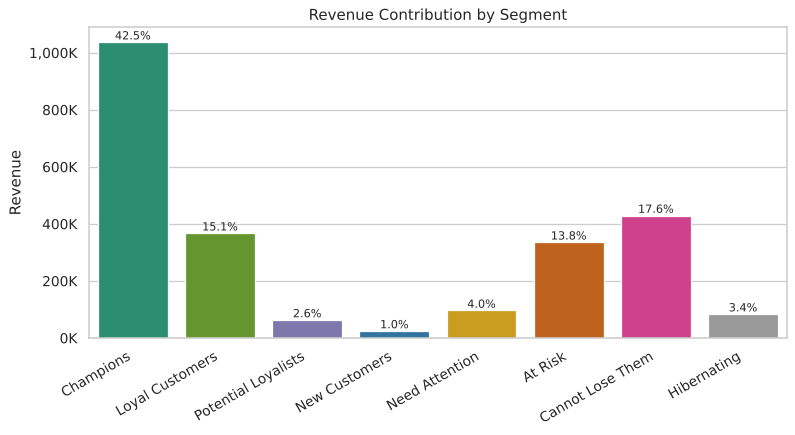

In [20]:
# ---- Chart 2: Revenue contribution by segment ----
rev = rfm.groupby("Segment")["Monetary"].sum().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=rev.index, y=rev.values, hue=rev.index, palette=SEGMENT_COLORS, legend=False, ax=ax)
for i, v in enumerate(rev.values):
    ax.text(i, v, f"{v / rev.sum():.1%}", ha="center", va="bottom", fontsize=9)
ax.set(title="Revenue Contribution by Segment", xlabel="", ylabel="Revenue")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}K"))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
save(fig, "02_revenue_by_segment.png"); plt.show()

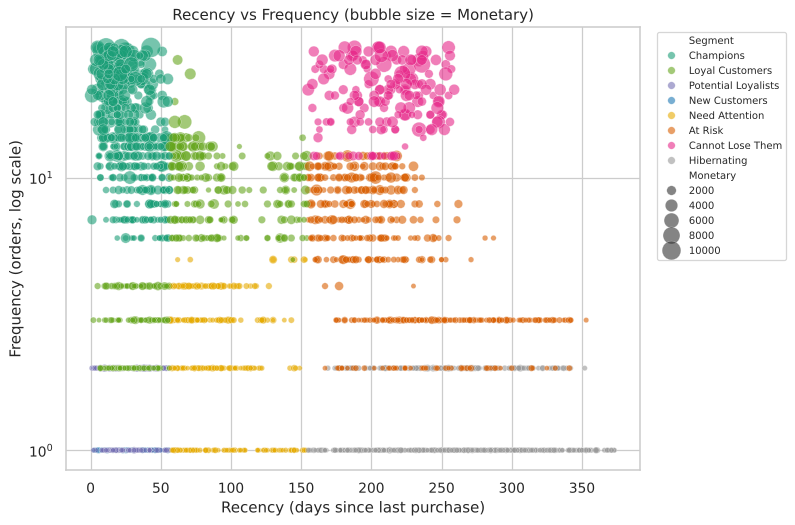

In [21]:
# ---- Chart 3: Recency vs Frequency scatter ----
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Recency", y="Frequency", hue="Segment", palette=SEGMENT_COLORS,
                hue_order=SEGMENT_ORDER, size="Monetary", sizes=(15, 250), alpha=0.6, ax=ax)
ax.set_yscale("log")
ax.set(title="Recency vs Frequency (bubble size = Monetary)",
       xlabel="Recency (days since last purchase)", ylabel="Frequency (orders, log scale)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
save(fig, "03_recency_vs_frequency.png"); plt.show()

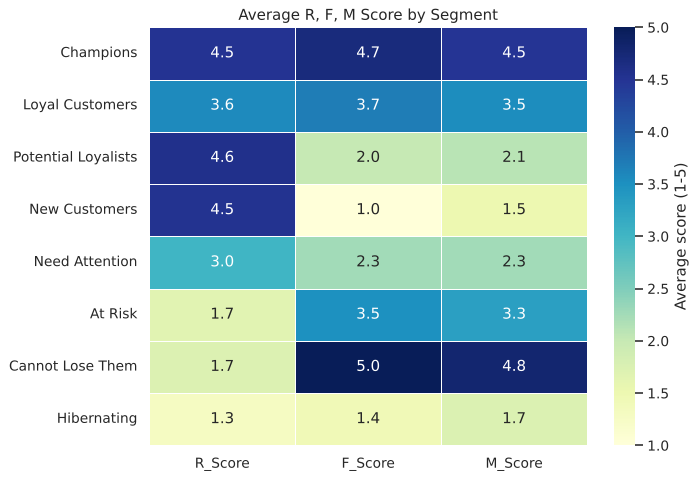

In [22]:
# ---- Chart 4: RFM score comparison (heatmap) ----
avg = rfm.groupby("Segment")[["R_Score", "F_Score", "M_Score"]].mean().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(avg, annot=True, fmt=".1f", cmap="YlGnBu", vmin=1, vmax=5, linewidths=.5,
            cbar_kws={"label": "Average score (1-5)"}, ax=ax)
ax.set(title="Average R, F, M Score by Segment", xlabel="", ylabel="")
save(fig, "04_rfm_score_comparison.png"); plt.show()

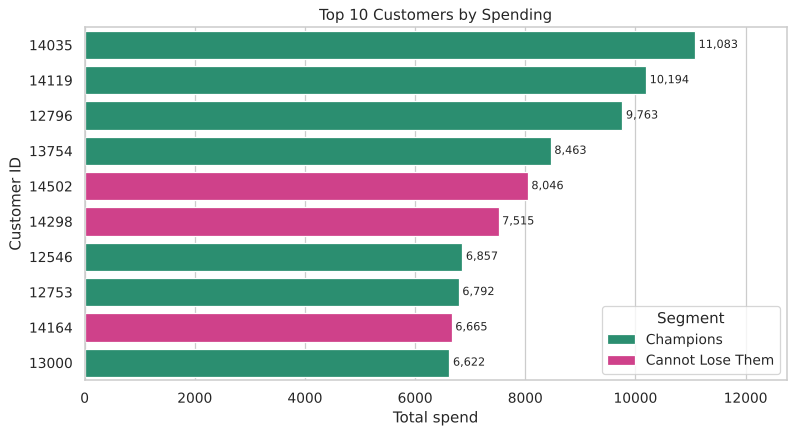

In [23]:
# ---- Chart 5: Top 10 customers by spending ----
top = rfm.nlargest(10, "Monetary").copy()
top["CustomerID"] = top["CustomerID"].astype(str)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top, x="Monetary", y="CustomerID", hue="Segment", palette=SEGMENT_COLORS, dodge=False, ax=ax)
for i, v in enumerate(top["Monetary"]):
    ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
ax.set(title="Top 10 Customers by Spending", xlabel="Total spend", ylabel="Customer ID")
ax.set_xlim(0, top["Monetary"].max() * 1.15)
save(fig, "05_top10_customers.png"); plt.show()

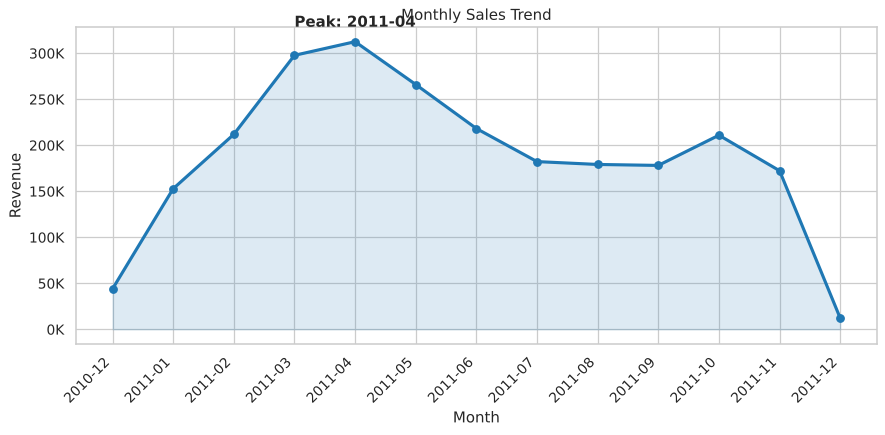

In [24]:
# ---- Chart 6: Monthly sales trend ----
m = clean.groupby("InvoiceMonth")["TotalSales"].sum()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(m.index, m.values, marker="o", lw=2.5, color="#1f78b4")
ax.fill_between(m.index, m.values, alpha=0.15, color="#1f78b4")
ax.annotate(f"Peak: {m.idxmax()}", (m.idxmax(), m.max()), xytext=(0, 12), textcoords="offset points",
            ha="center", fontweight="bold")
ax.set(title="Monthly Sales Trend", xlabel="Month", ylabel="Revenue")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}K"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "06_monthly_sales_trend.png"); plt.show()

**Practice 12:** Change the colour of Chart 6 and re-save it. Add a title and axis labels to a new chart: *Average Frequency by Segment*.

## Step 13 – Export results for SQL check and Power BI
**What:** Save clean transactions, RFM table and segment summary as CSV.
**Why:** Power BI reads these files. They are also your *proof* that Python and SQL results match.

In [25]:
OUT = Path("..") / "outputs"
country = clean.groupby("CustomerID")["Country"].agg(lambda x: x.mode().iat[0]).rename("Country")
rfm_out = rfm.merge(country, on="CustomerID")
clean["InvoiceDay"] = clean["InvoiceDate"].dt.date

clean.drop(columns=["Weekday", "Hour"]).to_csv(OUT / "clean_transactions.csv", index=False)
rfm_out.to_csv(OUT / "rfm_customers.csv", index=False)
summary.to_csv(OUT / "segment_summary.csv")
print("Saved: clean_transactions.csv, rfm_customers.csv, segment_summary.csv")
print("Customers:", len(rfm_out), "| Revenue:", f"{clean['TotalSales'].sum():,.0f}")

Saved: clean_transactions.csv, rfm_customers.csv, segment_summary.csv
Customers: 2996 | Revenue: 2,438,542


## Project complete – interview summary
1. Cleaned the transactions (removed duplicates, missing IDs, cancellations, invalid values, non-product codes).
2. Calculated Recency, Frequency, Monetary per customer using a snapshot date.
3. Scored each metric 1-5 with quintiles and mapped to 8 business segments.
4. Found that a small group (Champions) generates a very large share of revenue and that valuable *At Risk / Cannot Lose Them* customers need win-back campaigns.
5. Reproduced the analysis in MySQL and delivered an interactive Power BI dashboard.

**Limitations to mention honestly:** RFM ignores product category and profit margin, scoring depends on the data period, and a 1-year window cannot separate seasonal buyers from churned customers.